# Session 3: a yes/no question with logistic regression

**Course link:** Machine Learning Specialization, Course 1 Week 3 (classification, the sigmoid, decision boundaries, logistic cost, gradient descent for logistic regression, overfitting and regularization).

**Question:** when a government consolidates (ΔCAPB ≥ 1.5 pp), can we tell in advance whether TFP growth over the next years will be **below the median**?

**Choices made before fitting anything:**
- Rows: the consolidation episodes from Session 2's sample. Every row is an episode, so the episode flag is always 1 and cannot be an input.
- Inputs: ΔCAPB and the four thesis controls from the year before, the same as Session 2 apart from the flag.
- Target: 1 if TFP growth from t−1 to t+2 is below the median of all country-years in the **training** countries, else 0.
- Extreme inflation is capped at ±30 %. Session 2 showed that Bulgaria's 1997 hyperinflation can dominate a linear model.
- Same six hidden countries as Sessions 1 and 2, plus the test with every country hidden in turn.
- Baseline: always predict the most common class in the training data. For log loss it predicts the training share of "yes" as its probability, because a flat 0 or 1 would give an infinite log loss when wrong.

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. How many consolidation episodes are there to learn from:
2. Share of episodes followed by below-median TFP growth (more or less than half):
3. On the six hidden countries, will the model beat the baseline on accuracy? On log loss?
4. Hiding each country in turn, accuracy of the model vs the baseline:
5. Which input matters most for "growth will be weak":
6. Which λ will work best (0 / 0.1 / 1 / 10 / 100):
7. Section 11 compares each episode with other countries in the same year. Will the model still beat the baseline then?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm

pd.set_option("display.width", 140)
df = pd.read_csv(DATA_URL)
print(df.shape)

(780, 22)


## 1. Build the sample and the yes/no target

In [3]:
COUNTRY = "country"
YEAR    = "year"
DCAPB   = "dcapb_main"   # ΔCAPB, pp of GDP (+ = tightening)
TFP     = "tfp"
H = 2
CAP = 30                 # inflation capped at ±30 %, decided before fitting

CONTROLS_RAW = ["gdp_growth", "debt_gdp", "inflation", "trade_open"]
CONTROLS = [c + "_lag1" for c in CONTROLS_RAW]
INPUTS = [DCAPB] + CONTROLS

def add_columns(frame, cap=CAP):
    d = frame.sort_values([COUNTRY, YEAR]).copy()
    if cap is not None:
        d["inflation"] = d["inflation"].clip(-cap, cap)
    d["log_tfp"] = np.log(d[TFP])
    lead = d.groupby(COUNTRY)["log_tfp"].shift(-H)
    lag1 = d.groupby(COUNTRY)["log_tfp"].shift(1)
    d["growth"] = 100 * (lead - lag1)          # % TFP growth, t-1 -> t+2 (Session 1's target)
    for raw, lagged in zip(CONTROLS_RAW, CONTROLS):
        d[lagged] = d.groupby(COUNTRY)[raw].shift(1)
    return d[[COUNTRY, YEAR, DCAPB, "growth"] + CONTROLS].dropna().reset_index(drop=True)

rows = add_columns(df)                        # Session 2's 669 rows: the median is taken from these
episodes = rows[rows[DCAPB] >= 1.5].reset_index(drop=True)

print("All rows:", len(rows), "| consolidation episodes:", len(episodes),
      "in", episodes[COUNTRY].nunique(), "countries")
print("Episodes per country:", episodes[COUNTRY].value_counts().sort_values().to_dict())

All rows: 669 | consolidation episodes: 96 in 24 countries
Episodes per country: {'Germany': 1, 'Belgium': 1, 'Sweden': 2, 'Spain': 2, 'Croatia': 2, 'Estonia': 3, 'Italy': 3, 'Austria': 3, 'Slovenia': 3, 'Poland': 3, 'Denmark': 4, 'Finland': 4, 'Romania': 4, 'Lithuania': 5, 'Cyprus': 5, 'Luxembourg': 5, 'Bulgaria': 5, 'Malta': 5, 'Latvia': 5, 'Hungary': 6, 'Greece': 6, 'Slovakia': 6, 'Ireland': 6, 'Portugal': 7}


Not many rows: about 100 episodes, and some countries have only one or two. Keep that in mind when reading every result below.

## 2. Logistic regression, vectorized

The model is f(x) = g(w·x + b), where g(z) = 1 / (1 + e⁻ᶻ) turns any number into a probability between 0 and 1. The cost is the log loss: confident wrong answers cost a lot. Regularization adds λ/(2m) · Σw² to keep the weights small; b is not regularized.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict_proba(X, w, b):
    return sigmoid(X @ w + b)

def log_loss(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)          # avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def compute_cost(X, y, w, b, lam):
    m = len(y)
    return log_loss(predict_proba(X, w, b), y) + lam / (2 * m) * np.sum(w ** 2)

def compute_gradient(X, y, w, b, lam):
    m = len(y)
    err = predict_proba(X, w, b) - y
    return (X.T @ err) / m + (lam / m) * w, err.mean()

def gradient_descent(X, y, alpha, lam=0.0, iters=2000):
    w, b = np.zeros(X.shape[1]), 0.0
    J_history = []
    for i in range(iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b, lam)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        J = compute_cost(X, y, w, b, lam)
        J_history.append(J)
        if not np.isfinite(J):
            break
    return w, b, J_history

def fit_scaler(frame, inputs):
    return frame[inputs].mean().to_numpy(), frame[inputs].std(ddof=0).to_numpy()

def scale(frame, inputs, mu, sigma):
    return (frame[inputs].to_numpy() - mu) / sigma

def to_original_units(w_scaled, b_scaled, mu, sigma):
    w = w_scaled / sigma
    return w, b_scaled - np.sum(w * mu)

## 3. Split by country, set the target, scale on the training countries only

The median that defines "below median" also comes from the training countries only.

In [5]:
rng = np.random.default_rng(42)
rows_s1 = df.sort_values([COUNTRY, YEAR]).assign(log_tfp=lambda d: np.log(d[TFP]))
rows_s1 = rows_s1.assign(y=100 * (rows_s1.groupby(COUNTRY)["log_tfp"].shift(-H) - rows_s1.groupby(COUNTRY)["log_tfp"].shift(1)))
rows_s1 = rows_s1[[COUNTRY, DCAPB, "y"]].dropna()
test_countries = rng.choice(rows_s1[COUNTRY].unique(), size=6, replace=False)
print("Hidden countries (same as Sessions 1 and 2):", sorted(test_countries))

def make_split(hidden, frame=rows, by_year=False):
    tr_all = frame[~frame[COUNTRY].isin(hidden)]
    if by_year:                                # section 11: one median per year
        median = tr_all.groupby(YEAR)["growth"].median()
    else:
        median = tr_all["growth"].median()    # from the training countries only
    tr = tr_all[tr_all[DCAPB] >= 1.5].copy()
    te = frame[frame[COUNTRY].isin(hidden) & (frame[DCAPB] >= 1.5)].copy()
    for d in (tr, te):
        cut = d[YEAR].map(median) if by_year else median
        d["weak"] = (d["growth"] < cut).astype(float)
    return tr, te, median

train, test, median = make_split(test_countries)
print(f"Median TFP growth in the training countries: {median:.2f} %")
print(f"Training episodes: {len(train)}, share weak {train['weak'].mean():.2f}")
print(f"Hidden-country episodes: {len(test)}, share weak {test['weak'].mean():.2f}")

mu, sigma = fit_scaler(train, INPUTS)
X_train, y_train = scale(train, INPUTS, mu, sigma), train["weak"].to_numpy()

Hidden countries (same as Sessions 1 and 2): ['Belgium', 'Greece', 'Lithuania', 'Malta', 'Slovakia', 'Spain']
Median TFP growth in the training countries: 2.84 %
Training episodes: 71, share weak 0.54
Hidden-country episodes: 25, share weak 0.40


## 4. Pick α the same way as Session 2

Values about ×3 apart, on training data only: take the largest α whose cost falls at every step.

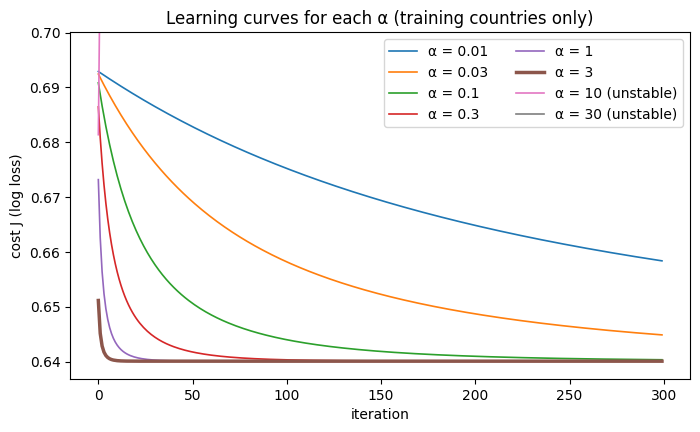

Chosen α: 3.0


In [6]:
ALPHAS = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]

def pick_alpha(X, y, lam=0.0, iters=300):
    curves, best = {}, None
    for a in ALPHAS:
        _, _, J = gradient_descent(X, y, alpha=a, lam=lam, iters=iters)
        curves[a] = J
        if len(J) == iters and np.all(np.diff(J) <= 1e-12):
            best = a
    return best, curves

alpha, curves = pick_alpha(X_train, y_train)
fig, ax = plt.subplots(figsize=(8, 4.5))
for a, J in curves.items():
    stable = len(J) == 300 and np.all(np.diff(J) <= 1e-12)
    ax.plot(J, label=f"α = {a:g}" + ("" if stable else " (unstable)"), lw=2.5 if a == alpha else 1.2)
ax.set_ylim(min(curves[alpha]) * 0.995, np.log(2) * 1.01)
ax.set_title("Learning curves for each α (training countries only)")
ax.set_xlabel("iteration"); ax.set_ylabel("cost J (log loss)"); ax.legend(ncol=2); plt.show()
print("Chosen α:", alpha)

## 5. Train, and check against scikit-learn and statsmodels

With λ = 0, all three should find the same weights. For λ > 0, scikit-learn's `C` equals 1/λ in the course's version of the cost.

                 gradient descent  scikit-learn  statsmodels
intercept b               -1.2572       -1.2572      -1.2572
dcapb_main                 0.1403        0.1403       0.1403
gdp_growth_lag1           -0.0495       -0.0495      -0.0495
debt_gdp_lag1              0.0069        0.0069       0.0069
inflation_lag1             0.1347        0.1347       0.1347
trade_open_lag1            0.0022        0.0022       0.0022
Largest gap: 3.5e-05


With λ = 1 on scaled inputs, largest gap to scikit-learn (C = 1): 3.3e-04


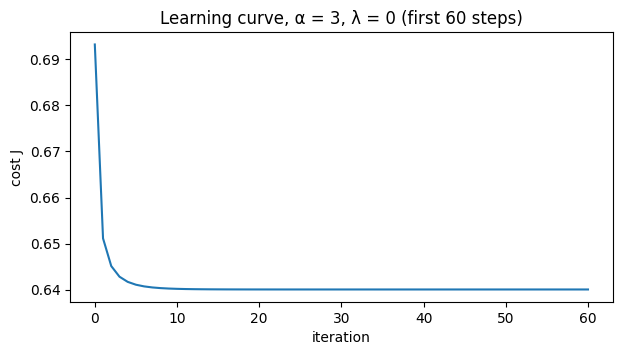

Cost at the start: 0.6931 (a 50/50 guess), after 60 steps: 0.6401, after 20,000: 0.6401


In [7]:
w_s, b_s, J_hist = gradient_descent(X_train, y_train, alpha=alpha, lam=0.0, iters=20000)
w_gd, b_gd = to_original_units(w_s, b_s, mu, sigma)

sk = LogisticRegression(penalty=None, max_iter=10000).fit(train[INPUTS], y_train)
smod = sm.Logit(y_train, sm.add_constant(train[INPUTS])).fit(disp=0)

check = pd.DataFrame({"gradient descent": np.r_[b_gd, w_gd],
                      "scikit-learn": np.r_[sk.intercept_, sk.coef_[0]],
                      "statsmodels": smod.params.to_numpy()}, index=["intercept b"] + INPUTS)
print(check.round(4))
print("Largest gap:", f"{np.max(np.abs(check.to_numpy() - check[['gradient descent']].to_numpy())):.1e}")

w_l, b_l, _ = gradient_descent(X_train, y_train, alpha=alpha, lam=1.0, iters=20000)
sk_l = LogisticRegression(C=1.0, max_iter=10000).fit(X_train, y_train)
print(f"With λ = 1 on scaled inputs, largest gap to scikit-learn (C = 1): {np.max(np.abs(np.r_[w_l, b_l] - np.r_[sk_l.coef_[0], sk_l.intercept_])):.1e}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(0, 61), [np.log(2)] + J_hist[:60])
ax.set_title(f"Learning curve, α = {alpha:g}, λ = 0 (first 60 steps)")
ax.set_xlabel("iteration"); ax.set_ylabel("cost J"); plt.show()
print(f"Cost at the start: {np.log(2):.4f} (a 50/50 guess), after 60 steps: {J_hist[59]:.4f}, after 20,000: {J_hist[-1]:.4f}")

## 6. Choose λ inside the training countries

The hidden countries must not be used to choose λ. A large λ makes each step bigger, so α is picked again for every λ, on the training countries only. So inside the 20 training countries, each one is left out in turn, trained on the rest and scored. The λ with the lowest log loss wins.

In [8]:
LAMBDAS = [0, 0.1, 1, 10, 100]

# A large λ makes each step bigger, so α is picked once for every λ on the training countries
ALPHA_FOR = {l: pick_alpha(X_train, y_train, lam=l)[0] for l in LAMBDAS}
print("α for each λ:", ALPHA_FOR)

def fit_model(tr, inputs, lam):
    m, s = fit_scaler(tr, inputs)
    w, b, _ = gradient_descent(scale(tr, inputs, m, s), tr["weak"].to_numpy(), alpha=ALPHA_FOR[lam], lam=lam, iters=1000)
    return m, s, w, b

def proba(model, te, inputs):
    m, s, w, b = model
    return predict_proba(scale(te, inputs, m, s), w, b)

def inner_cv(tr_countries, inputs, lam, frame=rows, by_year=False):
    # leave one training country out at a time; the median is recomputed every time
    ys, ps = [], []
    for c in tr_countries:
        others = [x for x in frame[COUNTRY].unique() if x not in tr_countries or x == c]
        tr, te, _ = make_split(others, frame, by_year)
        if len(te) == 0:
            continue
        ps.append(proba(fit_model(tr, inputs, lam), te, inputs)); ys.append(te["weak"].to_numpy())
    return log_loss(np.concatenate(ps), np.concatenate(ys))

def choose_lambda(tr_countries, inputs, frame=rows, by_year=False):
    scores = {lam: inner_cv(tr_countries, inputs, lam, frame, by_year) for lam in LAMBDAS}
    return min(scores, key=scores.get), scores

train_countries = [c for c in rows[COUNTRY].unique() if c not in test_countries]
lam, lam_scores = choose_lambda(train_countries, INPUTS)

table = []
for l in LAMBDAS:
    model = fit_model(train, INPUTS, l)
    table.append({"λ": l, "log loss, training countries left out in turn": round(lam_scores[l], 3),
                  "size of the weights (sum of |w|)": round(np.abs(model[2]).sum(), 2)})
print("Chosen λ:", lam)
pd.DataFrame(table).set_index("λ")

α for each λ: {0: 3.0, 0.1: 3.0, 1: 3.0, 10: 3.0, 100: 1.0}


Chosen λ: 10


,"log loss, training countries left out in turn",size of the weights (sum of |w|)
λ,,
0.0,0.741,1.75
0.1,0.736,1.71
1.0,0.711,1.49
10.0,0.680,0.78
100.0,0.690,0.17


## 7. The unseen-country test

Each model is trained on the 20 training countries, with λ chosen inside them, then scored on the episodes of the six hidden countries. Two smaller models show what each part of the inputs adds.

In [9]:
MODELS = {"Session 3: ΔCAPB + controls": INPUTS, "ΔCAPB only": [DCAPB], "Controls only": CONTROLS}

def scores(y, p, base_rate):
    majority = float(base_rate >= 0.5)
    return {"log loss": log_loss(p, y), "baseline log loss": log_loss(np.full(len(y), base_rate), y),
            "accuracy": np.mean((p >= 0.5) == y), "baseline accuracy": np.mean(majority == y)}

six = []
for name, inputs in MODELS.items():
    l, _ = choose_lambda(train_countries, inputs)
    p = proba(fit_model(train, inputs, l), test, inputs)
    s = scores(test["weak"].to_numpy(), p, train["weak"].mean())
    six.append({"model": name, "λ": l, **{k: round(v, 3) for k, v in s.items()},
                "log loss improvement %": round(100 * (1 - s["log loss"] / s["baseline log loss"]), 1)})
six = pd.DataFrame(six).set_index("model")
print(f"Hidden-country episodes: {len(test)}. Baseline predicts '{'weak' if train['weak'].mean() >= 0.5 else 'not weak'}' every time.")
six

Hidden-country episodes: 25. Baseline predicts 'weak' every time.


,λ,log loss,baseline log loss,accuracy,baseline accuracy,log loss improvement %
model,,,,,,
Session 3: ΔCAPB + controls,10,0.670,0.71,0.60,0.4,5.6
ΔCAPB only,1,0.693,0.71,0.44,0.4,2.3
Controls only,10,0.670,0.71,0.68,0.4,5.6


### Every country hidden in turn

The same test for each of the countries that have episodes. Inside each round, λ is chosen again without the hidden country. Many countries have only a few episodes, so the pooled numbers (all held-out episodes together) are the ones to read.

In [10]:
def leave_one_out(inputs, frame=rows, fixed_lambda=None, by_year=False):
    per_country, ys, ps, bs, ms = [], [], [], [], []
    ep_countries = frame.loc[frame[DCAPB] >= 1.5, COUNTRY].unique()
    for c in ep_countries:
        tr, te, _ = make_split([c], frame, by_year)
        l = fixed_lambda if fixed_lambda is not None else choose_lambda([x for x in frame[COUNTRY].unique() if x != c], inputs, frame, by_year)[0]
        p = proba(fit_model(tr, inputs, l), te, inputs)
        y, base = te["weak"].to_numpy(), tr["weak"].mean()
        ys.append(y); ps.append(p); bs.append(np.full(len(y), base)); ms.append(np.full(len(y), float(base >= 0.5)))
        per_country.append({COUNTRY: c, "episodes": len(y), "log loss": log_loss(p, y), "baseline": log_loss(np.full(len(y), base), y)})
    y, p, b, m = map(np.concatenate, (ys, ps, bs, ms))
    pooled = {"log loss": round(log_loss(p, y), 3), "baseline log loss": round(log_loss(b, y), 3),
              "log loss improvement %": round(100 * (1 - log_loss(p, y) / log_loss(b, y)), 1),
              "accuracy": round(np.mean((p >= 0.5) == y), 3), "baseline accuracy": round(np.mean(m == y), 3),
              "countries where log loss beats baseline": int(sum(r["log loss"] < r["baseline"] for r in per_country)),
              "countries": len(per_country)}
    return pooled, pd.DataFrame(per_country).set_index(COUNTRY)

loo = {}
for name, inputs in MODELS.items():
    loo[name] = leave_one_out(inputs)
pd.DataFrame({name: r[0] for name, r in loo.items()}).T

,log loss,baseline log loss,log loss improvement %,accuracy,baseline accuracy,countries where log loss beats baseline,countries
Session 3: ΔCAPB + controls,0.647,0.694,6.8,0.646,0.49,17.0,24.0
ΔCAPB only,0.664,0.694,4.3,0.594,0.49,13.0,24.0
Controls only,0.640,0.694,7.8,0.615,0.49,14.0,24.0


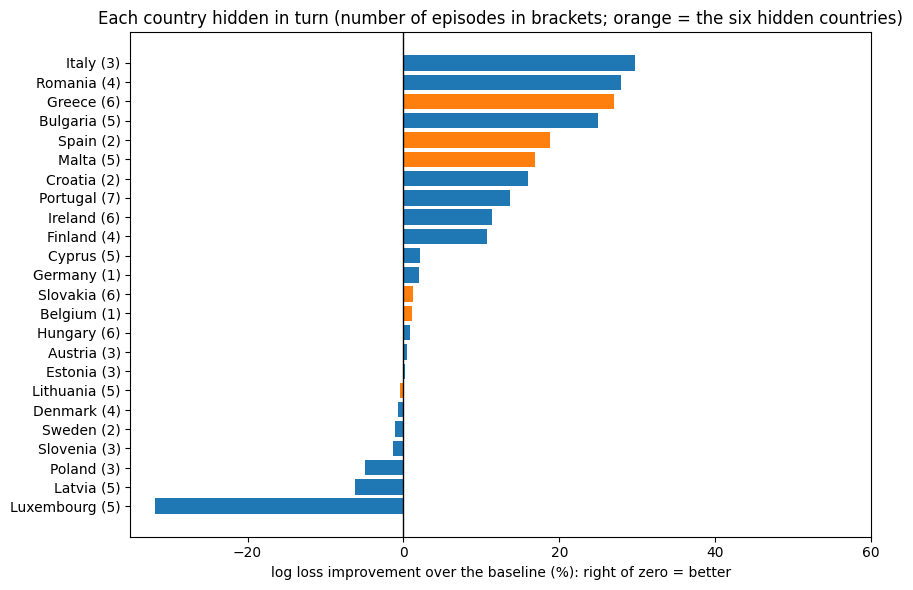

In [11]:
r = loo["Session 3: ΔCAPB + controls"][1]
imp = (100 * (1 - r["log loss"] / r["baseline"])).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([f"{c} ({int(r.loc[c, 'episodes'])})" for c in imp.index], imp.values,
        color=np.where(imp.index.isin(test_countries), "tab:orange", "tab:blue"))
ax.axvline(0, color="black", lw=1)
ax.set_xlim(max(-150, imp.min() * 1.1), max(60, imp.max() * 1.1))
ax.set_title("Each country hidden in turn (number of episodes in brackets; orange = the six hidden countries)")
ax.set_xlabel("log loss improvement over the baseline (%): right of zero = better")
plt.tight_layout(); plt.show()

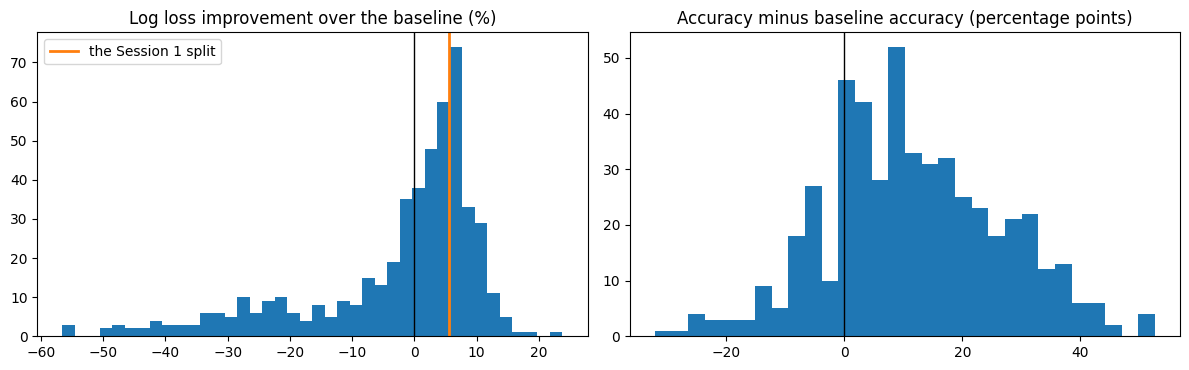

Log loss: median improvement 2.3 %, better than baseline in 60 % of splits
Accuracy: median gain 10.0 points, better than baseline in 74 % of splits


In [12]:
# How lucky is one split? 500 random sets of six hidden countries (λ fixed at the value chosen in section 6, for speed)
def many_splits(lam, by_year=False, n=500):
    rng_many = np.random.default_rng(0)
    countries = rows.loc[rows[DCAPB] >= 1.5, COUNTRY].unique()
    many_ll, many_acc = [], []
    for i in range(n):
        h = rng_many.choice(countries, size=6, replace=False)
        tr, te, _ = make_split(h, rows, by_year)
        s = scores(te["weak"].to_numpy(), proba(fit_model(tr, INPUTS, lam), te, INPUTS), tr["weak"].mean())
        many_ll.append(100 * (1 - s["log loss"] / s["baseline log loss"])); many_acc.append(s["accuracy"] - s["baseline accuracy"])
    return np.array(many_ll), np.array(many_acc)

many_ll, many_acc = many_splits(lam)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(np.clip(many_ll, -100, None), bins=40); ax[0].axvline(0, color="black", lw=1)
ax[0].axvline(six.loc["Session 3: ΔCAPB + controls", "log loss improvement %"], color="tab:orange", lw=2, label="the Session 1 split")
ax[0].set_title("Log loss improvement over the baseline (%)"); ax[0].legend()
ax[1].hist(100 * np.array(many_acc), bins=30); ax[1].axvline(0, color="black", lw=1)
ax[1].set_title("Accuracy minus baseline accuracy (percentage points)")
plt.tight_layout(); plt.show()
print(f"Log loss: median improvement {np.median(many_ll):.1f} %, better than baseline in {100*np.mean(np.array(many_ll) > 0):.0f} % of splits")
print(f"Accuracy: median gain {100*np.median(many_acc):.1f} points, better than baseline in {100*np.mean(np.array(many_acc) > 0):.0f} % of splits")

## 8. What the model says, and how sure it is

A logit fitted on all episodes, with country-clustered standard errors as in the thesis. Positive coefficients raise the chance of weak growth. The chart shows the decision boundary for ΔCAPB, with the controls held at their averages.

All 96 episodes, median 3.05 %, share weak 0.51
                 Coef.  Std.Err.      z  P>|z|
const           -1.390     0.842 -1.651  0.099
dcapb_main       0.108     0.084  1.284  0.199
gdp_growth_lag1 -0.094     0.064 -1.464  0.143
debt_gdp_lag1    0.011     0.007  1.670  0.095
inflation_lag1   0.081     0.041  1.966  0.049
trade_open_lag1  0.003     0.006  0.481  0.631


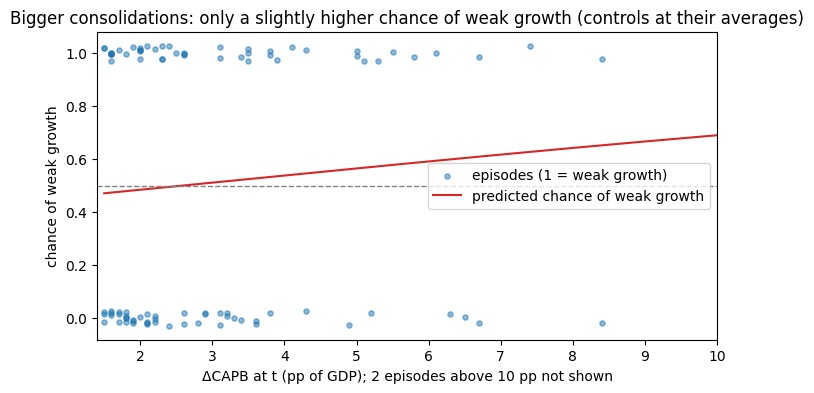

In [13]:
all_tr, _, all_median = make_split([])
logit = sm.Logit(all_tr["weak"], sm.add_constant(all_tr[INPUTS])).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(all_tr[COUNTRY])[0]})
print(f"All {len(all_tr)} episodes, median {all_median:.2f} %, share weak {all_tr['weak'].mean():.2f}")
print(logit.summary2().tables[1][["Coef.", "Std.Err.", "z", "P>|z|"]].round(3))

xs = np.linspace(1.5, 10, 200)
X_line = pd.DataFrame({c: all_tr[c].mean() for c in CONTROLS}, index=range(len(xs)))
X_line.insert(0, DCAPB, xs)
p_line = logit.predict(sm.add_constant(X_line, has_constant="add"))
fig, ax = plt.subplots(figsize=(8, 4))
jitter = np.random.default_rng(1).uniform(-0.03, 0.03, len(all_tr))
ax.scatter(all_tr[DCAPB], all_tr["weak"] + jitter, s=14, alpha=0.5, label="episodes (1 = weak growth)")
ax.plot(xs, p_line, color="tab:red", label="predicted chance of weak growth")
ax.axhline(0.5, ls="--", color="grey", lw=1)
ax.set_xlim(1.4, 10); ax.set_xlabel(f"ΔCAPB at t (pp of GDP); {int((all_tr[DCAPB] > 10).sum())} episodes above 10 pp not shown"); ax.set_ylabel("chance of weak growth")
ax.set_title("Bigger consolidations: only a slightly higher chance of weak growth (controls at their averages)")
ax.legend(); plt.show()

## 9. Check: inflation without the cap

The same tests with Bulgaria's extreme inflation left in, to see how much the choice made at the start matters.

In [14]:
uncapped = add_columns(df, cap=None)
tr_u, te_u, _ = make_split(test_countries, uncapped)
l_u, _ = choose_lambda(train_countries, INPUTS, uncapped)
s = scores(te_u["weak"].to_numpy(), proba(fit_model(tr_u, INPUTS, l_u), te_u, INPUTS), tr_u["weak"].mean())
print(f"Six hidden countries, uncapped: λ = {l_u}, log loss {s['log loss']:.3f} vs baseline {s['baseline log loss']:.3f}, accuracy {s['accuracy']:.3f} vs {s['baseline accuracy']:.3f}")
print("Every country hidden in turn, uncapped:", leave_one_out(INPUTS, uncapped)[0])

Six hidden countries, uncapped: λ = 10, log loss 0.653 vs baseline 0.710, accuracy 0.640 vs 0.400


Every country hidden in turn, uncapped: {'log loss': np.float64(0.641), 'baseline log loss': np.float64(0.694), 'log loss improvement %': np.float64(7.6), 'accuracy': np.float64(0.656), 'baseline accuracy': np.float64(0.49), 'countries where log loss beats baseline': 17, 'countries': 24}


## 10. Is it the consolidation, or the timing?

"Weak" compares each episode with the median of *all* years. If some periods were weak for everyone, such as the crisis years, the model can score by recognising the period rather than anything about the consolidation.

In [15]:
periods = pd.cut(all_tr[YEAR], [1990, 2007, 2013, 2030], labels=["1997-2007", "2008-2013", "2014-2022"])
timing = pd.DataFrame({"episodes": all_tr.groupby(periods, observed=True).size(),
                       "share weak": all_tr.groupby(periods, observed=True)["weak"].mean().round(2),
                       "average predicted chance": pd.Series(logit.predict(), index=all_tr.index).groupby(periods, observed=True).mean().round(2)})
timing

,episodes,share weak,average predicted chance
year,,,
1997-2007,34,0.41,0.47
2008-2013,33,0.64,0.57
2014-2022,29,0.48,0.48


## 11. Year-adjusted check: compare each episode with its own year

The target is redefined: 1 if the episode's TFP growth (t−1 to t+2) is below the median of all **training-country** observations in the **same year**, else 0. The yearly medians are recalculated without the hidden countries each time. A crisis year that was weak for everyone no longer counts as "weak" by itself, so the model can only score by telling consolidations apart within a year.

Everything else is identical: the same 96 episodes, the same inputs, inflation capped at ±30 %, α picked for each λ by the section 4 rule, λ chosen inside the training countries, the majority-class baseline, the six hidden countries, every country hidden in turn, and the 500 random splits.

In [16]:
train_y, test_y, medians_y = make_split(test_countries, by_year=True)
print(f"Yearly medians in the training countries: from {medians_y.min():.2f} % ({medians_y.idxmin()}) to {medians_y.max():.2f} % ({medians_y.idxmax()})")
print(f"Training episodes: {len(train_y)}, share weak {train_y['weak'].mean():.2f}")
print(f"Hidden-country episodes: {len(test_y)}, share weak {test_y['weak'].mean():.2f}")

# α picked again for every λ with the new target, by the same rule as section 6
mu_y, sigma_y = fit_scaler(train_y, INPUTS)
alpha_year = {l: pick_alpha(scale(train_y, INPUTS, mu_y, sigma_y), train_y["weak"].to_numpy(), lam=l)[0] for l in LAMBDAS}
print("α for each λ:", alpha_year, "| same as section 6:", alpha_year == ALPHA_FOR)
ALPHA_FOR = alpha_year

lam_y, lam_scores_y = choose_lambda(train_countries, INPUTS, by_year=True)
print("Chosen λ:", lam_y, "| inner log loss per λ:", {l: round(v, 3) for l, v in lam_scores_y.items()})

Yearly medians in the training countries: from -4.24 % (2007) to 6.64 % (1998)
Training episodes: 71, share weak 0.55
Hidden-country episodes: 25, share weak 0.40
α for each λ: {0: 3.0, 0.1: 3.0, 1: 3.0, 10: 3.0, 100: 1.0} | same as section 6: True


Chosen λ: 10 | inner log loss per λ: {0: np.float64(0.7), 0.1: np.float64(0.697), 1: np.float64(0.685), 10: np.float64(0.669), 100: np.float64(0.682)}


In [17]:
# The three tests with the year-adjusted target (this cell takes a few minutes)
s_y = scores(test_y["weak"].to_numpy(), proba(fit_model(train_y, INPUTS, lam_y), test_y, INPUTS), train_y["weak"].mean())
loo_y = leave_one_out(INPUTS, by_year=True)
many_ll_y, many_acc_y = many_splits(lam_y, by_year=True)

def summary(lam_, six_, loo_, ll_, acc_, share_weak):
    pooled = loo_[0]
    return {"λ chosen (six hidden split)": lam_,
            "share of the 96 episodes that are weak": f"{100 * share_weak:.0f} %",
            "six hidden: log loss vs baseline": f"{six_['log loss']:.3f} vs {six_['baseline log loss']:.3f}",
            "six hidden: accuracy vs baseline": f"{100 * six_['accuracy']:.0f} % vs {100 * six_['baseline accuracy']:.0f} %",
            "each hidden in turn: log loss vs baseline": f"{pooled['log loss']:.3f} vs {pooled['baseline log loss']:.3f} ({pooled['log loss improvement %']:+.1f} %)",
            "each hidden in turn: accuracy vs baseline": f"{100 * pooled['accuracy']:.1f} % vs {100 * pooled['baseline accuracy']:.1f} %",
            "each hidden in turn: countries where log loss beats baseline": f"{pooled['countries where log loss beats baseline']} of {pooled['countries']}",
            "500 splits: log loss better than baseline": f"{100 * np.mean(ll_ > 0):.0f} % of splits (median {np.median(ll_):+.1f} %)",
            "500 splits: accuracy better than baseline": f"{100 * np.mean(acc_ > 0):.0f} % of splits (median {100 * np.median(acc_):+.1f} points)"}

all_y, _, _ = make_split([], by_year=True)
compare = pd.DataFrame({
    "Original: median of all years": summary(lam, six.loc["Session 3: ΔCAPB + controls"], loo["Session 3: ΔCAPB + controls"],
                                             many_ll, many_acc, all_tr["weak"].mean()),
    "Year-adjusted: median of the same year": summary(lam_y, s_y, loo_y, many_ll_y, many_acc_y, all_y["weak"].mean())})
compare

,Original: median of all years,Year-adjusted: median of the same year
λ chosen (six hidden split),10,10
share of the 96 episodes that are weak,51 %,52 %
six hidden: log loss vs baseline,0.670 vs 0.710,0.674 vs 0.718
six hidden: accuracy vs baseline,60 % vs 40 %,56 % vs 40 %
each hidden in turn: log loss vs baseline,0.647 vs 0.694 (+6.8 %),0.638 vs 0.700 (+8.8 %)
each hidden in turn: accuracy vs baseline,64.6 % vs 49.0 %,60.4 % vs 42.7 %
each hidden in turn: countries where log loss beats baseline,17 of 24,13 of 24
500 splits: log loss better than baseline,60 % of splits (median +2.3 %),52 % of splits (median +0.2 %)
500 splits: accuracy better than baseline,74 % of splits (median +10.0 points),72 % of splits (median +10.0 points)


In [18]:
# Does the timing pattern from section 10 disappear? And what does the logit say now?
periods_y = pd.cut(all_y[YEAR], [1990, 2007, 2013, 2030], labels=["1997-2007", "2008-2013", "2014-2022"])
print(pd.DataFrame({"episodes": all_y.groupby(periods_y, observed=True).size(),
                    "share weak, original": all_tr.groupby(periods, observed=True)["weak"].mean().round(2),
                    "share weak, year-adjusted": all_y.groupby(periods_y, observed=True)["weak"].mean().round(2)}))
logit_y = sm.Logit(all_y["weak"], sm.add_constant(all_y[INPUTS])).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(all_y[COUNTRY])[0]})
print()
print(logit_y.summary2().tables[1][["Coef.", "Std.Err.", "z", "P>|z|"]].round(3))

           episodes  share weak, original  share weak, year-adjusted
year                                                                
1997-2007        34                  0.41                       0.56
2008-2013        33                  0.64                       0.52
2014-2022        29                  0.48                       0.48

                 Coef.  Std.Err.      z  P>|z|
const           -0.899     0.880 -1.021  0.307
dcapb_main       0.081     0.090  0.905  0.366
gdp_growth_lag1 -0.051     0.047 -1.087  0.277
debt_gdp_lag1    0.013     0.009  1.491  0.136
inflation_lag1   0.086     0.051  1.686  0.092
trade_open_lag1 -0.002     0.006 -0.346  0.729


# Learning log, Session 3 (5 Nov 2026)

**Course:** Machine Learning Specialization, Course 1 Week 3 (classification, sigmoid, decision boundary, logistic cost, gradient descent for logistic regression, overfitting, regularization)

**Setup, decided before fitting:**
- Rows: the 96 consolidation episodes (ΔCAPB ≥ 1.5 pp) in Session 2's rows, from 24 countries. Some countries have only one or two episodes.
- Target: 1 if TFP growth from t−1 to t+2 is below the median of all country-years in the training countries. The median is recomputed without the hidden countries every time. 51 % of all episodes are "weak".
- Inputs: ΔCAPB and the four lagged controls. The episode flag is always 1 here, so it is dropped.
- Inflation is capped at ±30 %, as Session 2 recommended deciding up front.
- Baseline: always predict the most common training class. For log loss it uses the training share of "weak" as its probability.

**Method**
- Vectorized gradient descent for logistic regression.
- With λ = 0 it matches scikit-learn and statsmodels to 4 decimals (largest gap 3.5e-05). With λ = 1 it matches scikit-learn with C = 1/λ (gap 3.3e-04).
- α was chosen as in Session 2: values about ×3 apart, on training data only. α = 3 for λ up to 10, but λ = 100 needs α = 1. My first run reused one α for every λ, and gradient descent blew up at λ = 100, so α is now picked for each λ.
- λ ∈ {0, 0.1, 1, 10, 100}, chosen by leaving one training country out at a time, without the hidden countries. On the Session 1 training split, λ = 10 wins (log loss 0.680, against 0.741 with no regularization). Regularization helps, which fits a small sample with weak signal.

**Prediction: a small, unsteady gain**

| Model | Six hidden: log loss vs baseline | Six hidden: accuracy vs baseline | Each hidden in turn: log loss vs baseline | Each hidden in turn: accuracy vs baseline | Countries where log loss beats baseline |
|---|---|---|---|---|---|
| **ΔCAPB + controls** | **0.670 vs 0.710 (+5.6 %)** | **60 % vs 40 %** | **0.647 vs 0.694 (+6.8 %)** | **64.6 % vs 49.0 %** | **17 of 24** |
| ΔCAPB only | 0.693 vs 0.710 (+2.3 %) | 44 % vs 40 % | 0.664 vs 0.694 (+4.3 %) | 59.4 % vs 49.0 % | 13 of 24 |
| Controls only | 0.670 vs 0.710 (+5.6 %) | 68 % vs 40 % | 0.640 vs 0.694 (+7.8 %) | 61.5 % vs 49.0 % | 14 of 24 |

- Unlike Sessions 1 and 2, the model does better than the baseline in the fairer test too, not only on one split. But the gain is small.
- Over 500 random sets of six hidden countries, log loss beats the baseline in 60 % of splits (median +2.3 %), and accuracy in 74 % (median +10 points).
- The baseline is weak here, because the classes are almost 50/50 and the majority class flips between rounds. Always guessing "weak" on all 96 episodes would be right 51 % of the time.
- Results vary a lot by country: Luxembourg and Latvia go wrong, Italy and Romania go well.
- Without the inflation cap, the results barely change (each hidden in turn: +7.6 %, accuracy 65.6 %), so the cap was not decisive.

**What the model says**
- Logit on all 96 episodes, country-clustered standard errors: only lagged inflation is significant at 5 % (0.081, p = 0.049). ΔCAPB is positive but not significant (0.108, p = 0.199).
- Controls alone predict as well as controls plus ΔCAPB. So the size of the consolidation adds little; the economic conditions around it matter more.
- Timing matters: 64 % of episodes in 2008–2013 were followed by weak growth, against 41 % in 1997–2007 and 48 % in 2014–2022. Because "weak" compares each episode with all years, part of what the model picks up is the period, not the consolidation.

**Year-adjusted check (added 5 Nov 2026)**
- Target redefined: 1 if the episode's TFP growth is below the median of all training-country observations in the **same year**. The yearly medians are recalculated without the hidden countries each time (they range from −4.24 % in 2007 to 6.64 % in 1998). Everything else is identical: the same 96 episodes, inputs, ±30 % inflation cap, α rule (same α for every λ as before), λ chosen inside the training countries (λ = 10 again), majority-class baseline, and all three tests.

| Test | Original: median of all years | Year-adjusted: median of the same year |
|---|---|---|
| Share of the 96 episodes that are weak | 51 % | 52 % |
| Six hidden: log loss vs baseline | 0.670 vs 0.710 (+5.6 %) | 0.674 vs 0.718 (+6.1 %) |
| Six hidden: accuracy vs baseline | 60 % vs 40 % | 56 % vs 40 % |
| Each hidden in turn: log loss vs baseline | 0.647 vs 0.694 (+6.8 %) | 0.638 vs 0.700 (+8.8 %) |
| Each hidden in turn: accuracy vs baseline | 64.6 % vs 49.0 % | 60.4 % vs 42.7 % |
| Each hidden in turn: countries where log loss beats baseline | 17 of 24 | 13 of 24 |
| 500 random splits: log loss better than baseline | 60 % of splits (median +2.3 %) | 52 % of splits (median +0.2 %) |
| 500 random splits: accuracy better than baseline | 74 % of splits (median +10 points) | 72 % of splits (median +10 points) |

- The timing pattern is gone: the share of weak episodes is now 56 % in 1997–2007, 52 % in 2008–2013 and 48 % in 2014–2022.
- The pooled log loss still looks better than the baseline, but the steadiness tests do not hold up: the model wins in only 13 of 24 countries and in 52 % of random splits, with a median gain of +0.2 %. That is a coin flip.
- The accuracy gains look steadier, but the baseline sets a low bar. With classes near 50/50, the majority class flips between rounds and its accuracy falls below 50 % (42.7 % with each country hidden in turn). Against a fair coin (50 %), the model's 60 % on 96 episodes is only about two standard errors better.
- Logit on all 96 episodes: no input is significant at 5 % any more. Inflation is the closest (p = 0.092); ΔCAPB has p = 0.366.
- **Conclusion:** most of the Session 3 signal was timing. Once each episode is compared with its own year, what is left is weak and unsteady, and ML still adds nothing reliable over the econometrics.

**Main lessons**
- Accuracy and log loss can tell different stories: log loss punishes confident mistakes.
- Regularization (λ = 10) helped in a small, noisy sample.
- Choosing α depends on λ. An α that works without regularization can blow up with a large λ.
- A predictor can work for the wrong reason. Here it partly recognised the crisis years; the year-adjusted check removed most of the gain. The thesis pre-trend caveat still applies, so this is not evidence about which consolidations *cause* weaker growth.
- A baseline that is wrong more than half the time is easy to beat. Check the accuracy against 50 % as well.

**Next idea:** add TFP growth before the episode as an input, to test the pre-trend.